# 06 — Spatial subsetting with AOI validation

**Goal:** define the area of interest once, validate it against the product grid, and hand it to
every later notebook through the session file. This notebook is the **single authority** for the AOI.

The AOI is given in longitude/latitude (WGS84). The product grid is in UTM (EPSG from notebook 02):
the four corners are projected and the enclosing window of grid pixels is computed.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nisar_s1.config import load_kit
from nisar_s1 import product as P

kit = load_kit()                                  # notebooks/kit_config.yaml
OUT = Path(kit["data_dir"]) / "outputs" / "06"   # outputs stay outside the repository
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
session = P.load_session(kit["session_file"], required=("granule", "frequency", "epsg"))
src_ctx = lambda: P.open_local_or_remote(session["gcov_local"], session["gcov_url"])

In [2]:
bbox = kit["aoi"]["bbox_wgs84"]
with src_ctx() as h5:
    prof = P.product_profile(h5)
grid = prof.grids[session["frequency"]]
bounds = P.lonlat_to_proj(bbox, grid.epsg)
win = P.window_from_bounds(grid, bounds)
area_km2 = (bounds[2] - bounds[0]) * (bounds[3] - bounds[1]) / 1e6
print("AOI (WGS84)        :", bbox)
print(f"AOI (EPSG:{grid.epsg}) :", [round(v) for v in bounds])
print(f"window rows {win.rows.start}:{win.rows.stop}, cols {win.cols.start}:{win.cols.stop} -> {win.shape} pixels, {area_km2:.1f} km²")

opening local file: NISAR_L2_PR_GCOV_034_144_A_026_2005_DHDH_M_20261103T041937_20261103T042013_P05036_N_F_J_001.h5
AOI (WGS84)        : [6.716, 47.885, 6.797, 47.935]
AOI (EPSG:32632) : [329250, 5305868, 335464, 5311601]
window rows 11295:11583, cols 4726:5038 -> (288, 312) pixels, 35.6 km²


## Validation rules
* the AOI must lie **inside** the grid (a partial overlap is accepted but reported);
* it must not be degenerate (at least 10 x 10 pixels);
* its memory footprint for all layers must stay small (here < 0.5 GB).

In [3]:
gx0, gy0, gx1, gy1 = grid.bounds
fully_inside = bounds[0] >= gx0 and bounds[2] <= gx1 and bounds[1] >= gy0 and bounds[3] <= gy1
from nisar_s1.polarimetry import memory_needed_gb
mem = memory_needed_gb(win.shape, n_arrays=len(grid.terms) + 3, itemsize=4)
print("fully inside the grid:", fully_inside)
print(f"memory for {len(grid.terms) + 3} float32 layers: {mem * 1024:.1f} MB")
for bad in [(0, 0, 100, 100)]:
    try:
        P.window_from_bounds(grid, bad)
    except ValueError as e:
        print("an AOI outside the product is rejected:", str(e)[:70], "...")

fully inside the grid: True
memory for 5 float32 layers: 1.7 MB
an AOI outside the product is rejected: AOI (0, 0, 100, 100) does not overlap the product grid (234720.0, 5178 ...


## The AOI on the image (HV, frequency A)

opening local file: NISAR_L2_PR_GCOV_034_144_A_026_2005_DHDH_M_20261103T041937_20261103T042013_P05036_N_F_J_001.h5


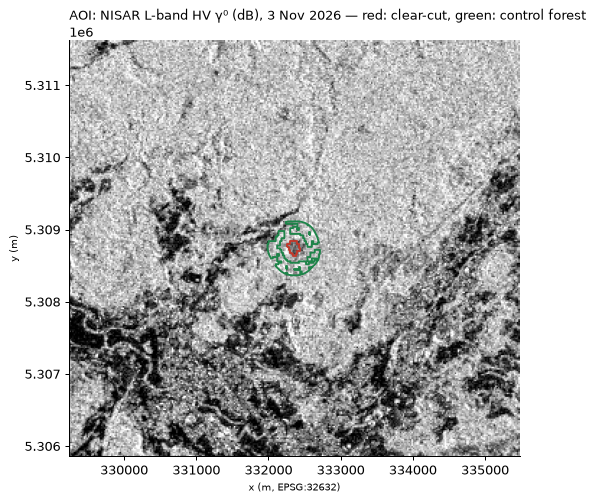

In [4]:
import geopandas as gpd
from nisar_s1.polarimetry import to_db
with src_ctx() as h5:
    hv = P.read_layer(h5, grid, "HVHV", win)
sites = gpd.read_file(kit["aoi"]["site_polygons"]).to_crs(grid.epsg)
x0 = win.transform.c; y0 = win.transform.f
ext = [x0, x0 + win.transform.a * win.shape[1], y0 + win.transform.e * win.shape[0], y0]
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(to_db(hv), cmap="gray", vmin=np.nanpercentile(to_db(hv), 2), vmax=np.nanpercentile(to_db(hv), 98), extent=ext)
sites.boundary.plot(ax=ax, color=["#c0392b" if r == "cut" else "#1e8449" for r in sites.role], lw=1.5)
ax.set_title("AOI: NISAR L-band HV γ⁰ (dB), 3 Nov 2026 — red: clear-cut, green: control forest", loc="left", fontsize=10)
ax.set_xlabel(f"x (m, EPSG:{grid.epsg})"); ax.set_ylabel("y (m)")
fig.savefig(OUT / "06_aoi_hv.png", dpi=110, bbox_inches="tight"); plt.show()

## Hand the AOI downstream

In [5]:
session = P.save_session(kit["session_file"], aoi_name=kit["aoi"]["name"], aoi_bbox_wgs84=bbox,
                         aoi_bounds=list(bounds), aoi_window=win.to_dict())
print("saved:", session["aoi_window"])

saved: {'rows': [11295, 11583], 'cols': [4726, 5038], 'transform': [20.0, 0.0, 329240.0, 0.0, -20.0, 5311620.0], 'crs': 'EPSG:32632'}


In [6]:
checks = {
    "AOI fully inside the grid": fully_inside,
    "AOI >= 10 x 10 pixels": min(win.shape) >= 10,
    "memory < 0.5 GB": mem < 0.5,
    "AOI saved": "aoi_window" in P.load_session(kit["session_file"]),
}
for k, v in checks.items():
    print(f"  [{'x' if v else ' '}] {k}")
assert all(checks.values()), "some checks failed: read the messages above"
print("Module 06 STATUS: PASS")

  [x] AOI fully inside the grid
  [x] AOI >= 10 x 10 pixels
  [x] memory < 0.5 GB
  [x] AOI saved
Module 06 STATUS: PASS
